In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Demostración: K-Means clustering

Nota: Ejemplo adaptado de "Hands on Machine Learning" de Geron Aurelien.

In [2]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

Creemos un data set sintético para demostrar el algoritmo de K-Means usando la función make_blobs de Scikit-Learn.

(2000, 2)


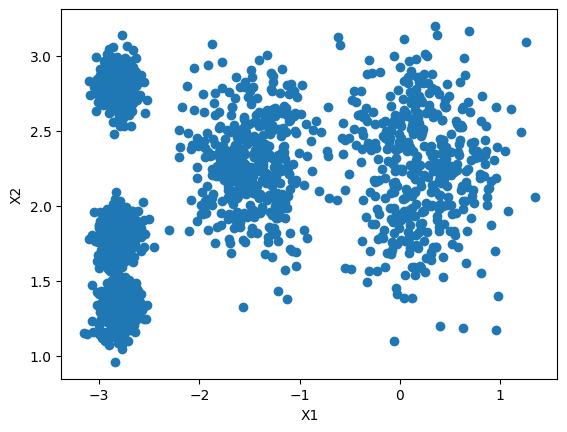

In [3]:
# Los centros de nuestros grupos, k=5
blob_centers = np.array([
    [ 0.2,  2.3],
    [-1.5 ,  2.3],
    [-2.8,  1.8],
    [-2.8,  2.8],
    [-2.8,  1.3]
])

# El "tamaño" de cada grupo (desviación estándar)
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])

X, y = make_blobs(
    n_samples=2000,
    centers=blob_centers,
    cluster_std=blob_std,
    random_state=7
)

print(X.shape)
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel('X1')
plt.ylabel('X2');

Ahora, creamos una instancia de la clase, sabemos que queremos 5 grupos, aunque no siempre estaremos seguros.

In [4]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=1, n_init='auto')
kmeans.fit(X)

y_pred = kmeans.predict(X)
# Esta información también se encuentra en KMeans().labels_
# ¿Para qué más podemos usar predict entonces?
y_pred

array([1, 4, 0, ..., 3, 0, 4], shape=(2000,), dtype=int32)

Los centroides estan almacenados en:

In [5]:
centroids = kmeans.cluster_centers_
centroids

array([[ 0.20876306,  2.25551336],
       [-2.80037642,  1.30082566],
       [-1.46679593,  2.28585348],
       [-2.79290307,  2.79641063],
       [-2.80389616,  1.80117999]])

Miremos la asignación de grupos.

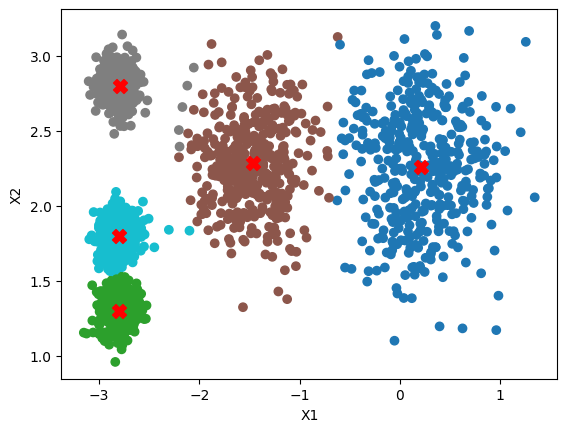

In [6]:
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='tab10')
plt.scatter(centroids[:, 0], centroids[:, 1], color='red', marker='X', s=100)
plt.xlabel('X1')
plt.ylabel('X2');

Podemos predecir el grupo de nuevas observaciones. Ojo, no se recalculan los centroides.

In [7]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
kmeans.predict(X_new)

array([0, 0, 3, 3], dtype=int32)

La distancia a los centroides se puede obtener con el método `transform`. Esto es similar a un "soft clustering".

In [8]:
kmeans.transform(X_new).round(2)

array([[0.33, 2.89, 1.49, 2.9 , 2.81],
       [2.8 , 5.84, 4.48, 5.85, 5.81],
       [3.29, 1.71, 1.69, 0.29, 1.21],
       [3.22, 1.22, 1.55, 0.36, 0.73]])

Recordemos que durante la presentación discutimos acerca de la inicialización del algoritmo y como una mala inicialización puede llevar a un resultado subóptimo. En Scikit-Learn podemos controlar este comportamiento con los parámetros `n_init` y `init`.
Con inicialización aleatoria es necesario repetir varias veces el algoritmo para encontrar una buena partición.

K-means++ es una forma de inicializar el algoritmo K-means de una manera más inteligente, para mantener los puntos de inicialización alejados entre sí.
Para realizar la inicialización, primero elige un centroide inicial al azar entre las observaciones en 𝑋. Luego, para los centroides restantes, elige el siguiente centroide entre los puntos restantes en 𝑋 con probabilidad proporcional a la distancia al cuadrado desde el centroide más cercano.

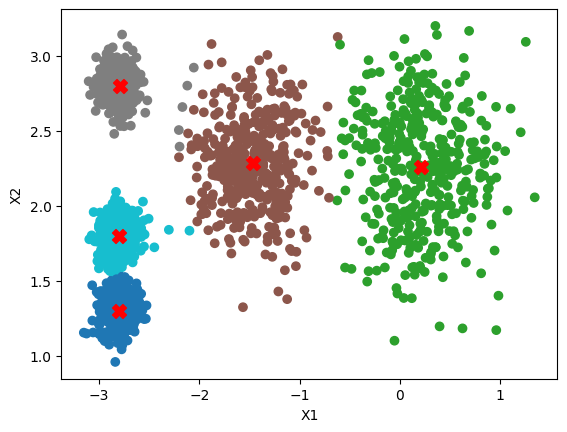

In [9]:
# Probemos la inicialización k-means++ con 100 arranques
kmeans = KMeans(n_clusters=k, init='k-means++', n_init=100, random_state=42)
y_pred = kmeans.fit_predict(X)
centroids = kmeans.cluster_centers_

plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='tab10')
plt.scatter(centroids[:, 0], centroids[:, 1], color='red', marker='X', s=100)
plt.xlabel('X1')
plt.ylabel('X2');

También es posible especificar la posición inicial de los centroides con `init` como arreglo; un ejemplo está al final del notebook.

Para seleccionar el mejor modelo, necesitaremos una forma de evaluar su rendimiento. Desafortunadamente, la agrupación es una tarea no supervisada, por lo que no tenemos las etiquetas. Pero podemos medir la distancia entre cada instancia y su centroide. A la suma de las distancias cuadradas a su centroide asignado se le llama inercia. De hecho, cuando ejecutamos KMeans con diferentes inicializaciones, el agoritmo elige la de menor inercia.

La inercia siempre disminuye con el número de grupos (k), pero podemos evaluar su tasa de cambio para encontrar el punto de inflexión. A este método se le conoce como el método del codo.

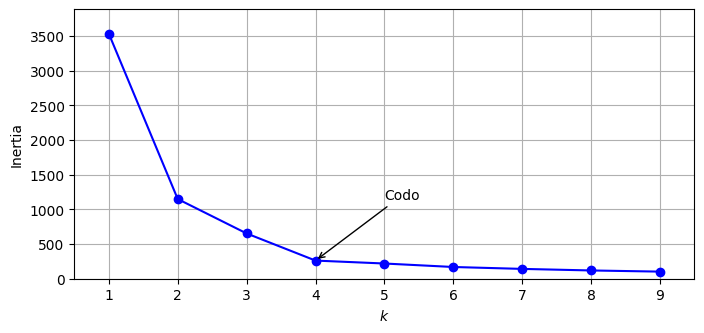

In [10]:
kmeans_per_k = [KMeans(n_clusters=k, n_init=10, init='k-means++', random_state=42).fit(X)
                for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.annotate("Codo", xy=(4, inertias[3]), xytext=(5, inertias[3] + 0.25 * max(inertias)),
             arrowprops=dict(arrowstyle="->"))
plt.xlim(0.5, 9.5)
plt.ylim(0, 1.1 * max(inertias))
plt.grid();

Parece que 4 grupos es una buena opción, aunque combina los grupos más pequeños.

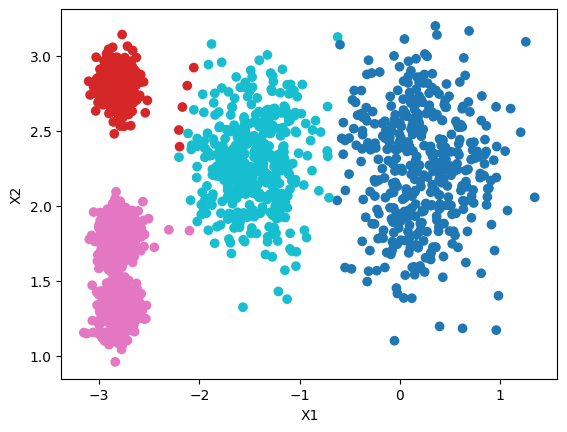

In [11]:
plt.scatter(X[:, 0], X[:, 1], c=kmeans_per_k[3].labels_, cmap='tab10')
plt.xlabel('X1')
plt.ylabel('X2');

Otro enfoque es observar la puntuación de silueta, que es el coeficiente de silueta medio sobre todas las observaciones. El coeficiente de silueta de una instancia es igual a $(b - a) / \max(a, b)$ donde $a$ es la distancia media a las otras instancias del mismo grupo y $b$ es la distancia media a las instancias del siguiente clúster más cercano (definido como el que minimiza $b$, excluyendo el propio clúster de la instancia). El coeficiente de silueta puede variar entre -1 y +1: un coeficiente cercano a +1 significa que la instancia está dentro de su propio grupo y lejos de otros grupos, mientras que un coeficiente cercano a 0 significa que está cerca del límite de un grupo. Y finalmente un coeficiente cercano a -1 significa que es posible que la instancia haya sido asignada al clúster incorrecto.

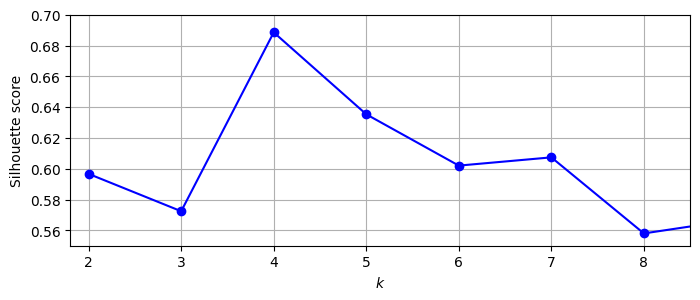

In [12]:
silhouette_scores = [
    silhouette_score(X, model.labels_)
    for model in kmeans_per_k[1:]
]

plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")
plt.axis([1.8, 8.5, 0.55, 0.7])
plt.grid();

Como puede ver, esta visualización es mucho más rica que la anterior: en particular, aunque confirma que $k=4$ es una muy buena elección, también subraya el hecho de que $k=5$ también es bastante buena.

Se obtiene una visualización aún más informativa cuando se traza el coeficiente de silueta de cada instancia, ordenado por el grupo al que están asignados y por el valor del coeficiente. Esto se llama diagrama de silueta:

In [13]:
from sklearn.metrics import silhouette_samples

def grafica_silueta(modelo, X, ax):
    """Diagrama de silueta: una barra por instancia, agrupada por cluster."""
    etiquetas = modelo.labels_
    valores = silhouette_samples(X, etiquetas)
    promedio = silhouette_score(X, etiquetas)

    y_inf = 10
    for c in np.unique(etiquetas):
        vals = np.sort(valores[etiquetas == c])
        y_sup = y_inf + len(vals)
        ax.fill_betweenx(np.arange(y_inf, y_sup), 0, vals, alpha=0.7)
        ax.text(-0.05, y_inf + 0.5 * len(vals), str(c))
        y_inf = y_sup + 10

    ax.axvline(promedio, color="red", linestyle="--", label=f"Promedio = {promedio:.2f}")
    ax.set_title(f"k = {modelo.n_clusters}")
    ax.set_xlabel("Coeficiente de silueta")
    ax.set_yticks([])
    ax.legend(loc="lower right")

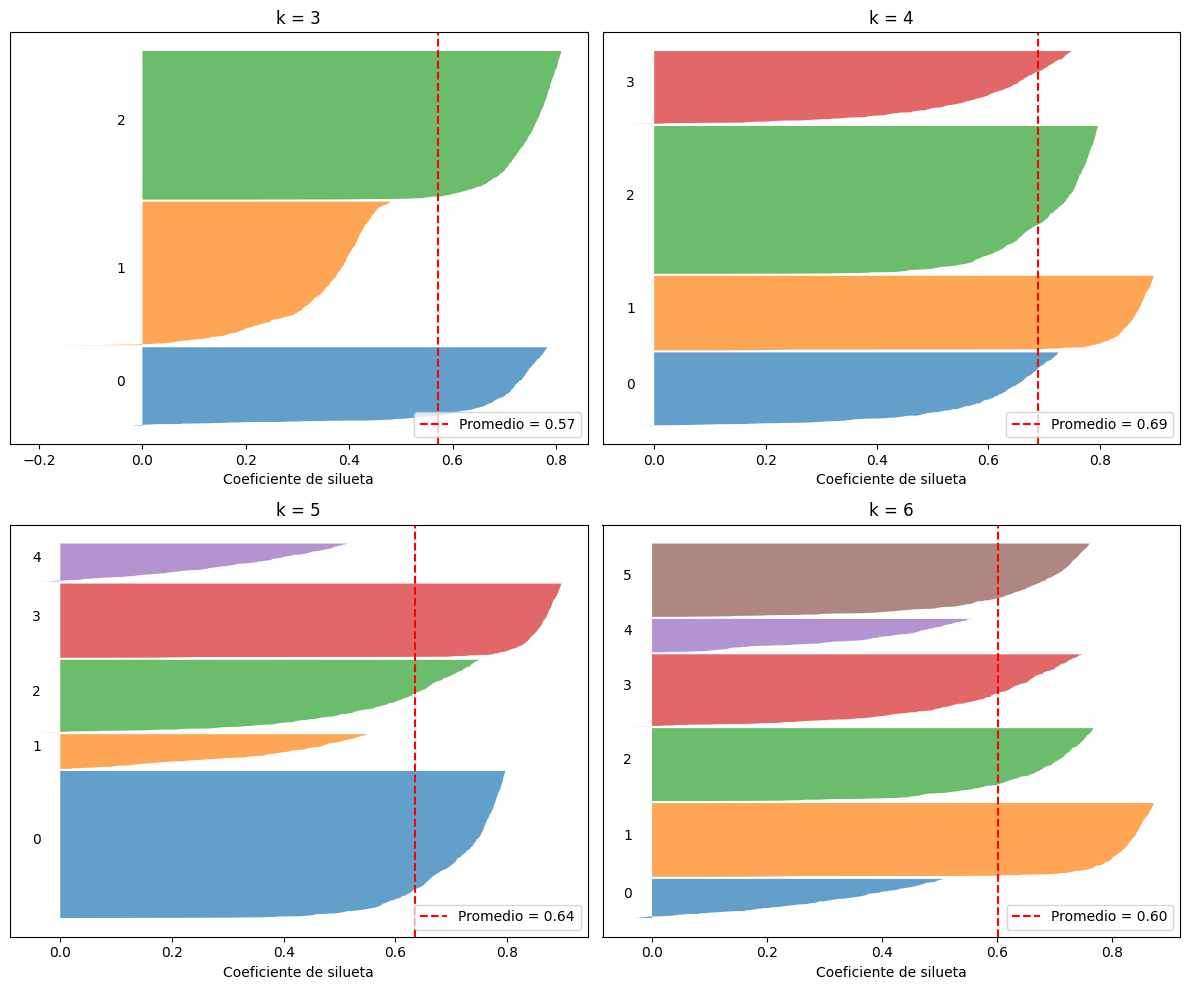

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for modelo, ax in zip(kmeans_per_k[2:6], axes.ravel()):
    grafica_silueta(modelo, X, ax)
plt.tight_layout()
plt.show()

Con este diagrama, **k=4** es el único valor en el que todos los grupos superan el promedio de la silueta (línea roja). Con **k=5**, que es el número real de grupos en estos datos, dos grupos quedan por debajo de la línea. Así que la silueta sugiere k=4 y el conocimiento de los datos sugiere k=5: conviene mirar ambas cosas.

Sin embargo, K-Means asume grupos esféricos, e intenta encontrar este tipo de grupos. Veamos que pasa si esta suposición no es correcta.

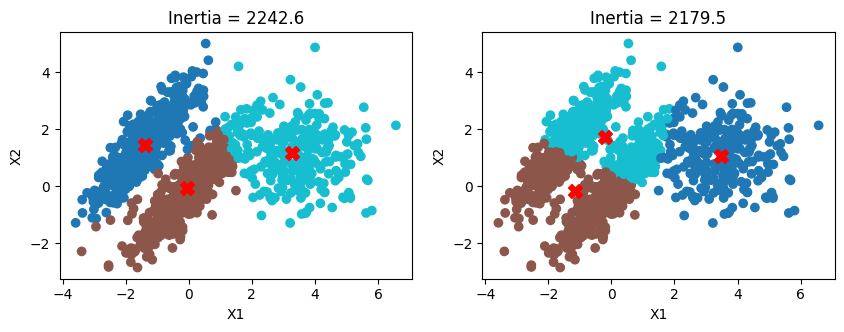

In [15]:
X1, y1 = make_blobs(n_samples=1000, centers=((4, -4), (0, 0)), random_state=42)
X1 = X1.dot(np.array([[0.374, 0.95], [0.732, 0.598]]))
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2 = X2 + [6, -8]
X = np.r_[X1, X2]
y = np.r_[y1, y2]

kmeans_good = KMeans(n_clusters=3,
                     init=np.array([[-1.5, 2.5], [0.5, 0], [4, 0]]),
                     n_init=1, random_state=42)
kmeans_bad = KMeans(n_clusters=3, random_state=42, n_init=100, init='k-means++')

kmeans_good.fit(X)
kmeans_bad.fit(X)

plt.figure(figsize=(10, 3.2))

plt.subplot(121)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_good.labels_, cmap='tab10')
plt.scatter(kmeans_good.cluster_centers_[:, 0], kmeans_good.cluster_centers_[:, 1], color='red', marker='X', s=100)
plt.xlabel('X1')
plt.ylabel('X2');
plt.title(f"Inertia = {kmeans_good.inertia_:.1f}")

plt.subplot(122)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_bad.labels_, cmap='tab10')
plt.scatter(kmeans_bad.cluster_centers_[:, 0], kmeans_bad.cluster_centers_[:, 1], color='red', marker='X', s=100)
plt.xlabel('X1')
plt.ylabel('X2');
plt.title(f"Inertia = {kmeans_bad.inertia_:.1f}");

**Lectura:** compara la inercia de ambas soluciones (título de cada gráfica). La solución con menor inercia no siempre es la que mejor refleja los grupos reales: K-Means asume grupos esféricos y aquí la nube de puntos es alargada, así que el resultado depende de cómo se ubiquen los centroides iniciales.